# Narrative Experiments: From HBM-Capacity to HBM-Bandwidth-Aware Agentic Serving

This notebook tests our **4-policy progression** across HBM budgets (`32, 40, 48, 64 GB`) and arrival rates (`λ = 0.15, 0.25`) on **Exgentic SWE-bench** (`Qwen/Qwen3.6-35B-A3B-FP8`):

1. **Policy 1 — Drop & Recompute (`vLLM static_full`):** Fills HBM to 100%; drops victim KV when full and re-prefills on the next turn.
2. **Policy 2 — Pack-HBM + Reactive Offload (`Full LRU` & `Paged Oracle` uncapped):** Offloads to DRAM instead of recomputing, but still packs HBM full of active `DECODE` jobs.
3. **Policy 3 — Bandwidth-Capped + Paged LRU (`B_cap=12 + Paged LRU`):** Caps active `PREFILL+DECODE` concurrency at the HBM-bandwidth knee (`B_cap=12`), using spare HBM as a warm `St.TOOL` buffer and LRU eviction when HBM fills.
4. **Policy 4 — Bandwidth-Capped + Paged Oracle (`B_cap=12 / R_cap=300k + Paged Oracle`):** Combines active-decode bandwidth capping with Belady-style Oracle eviction + proactive JIT prefetch when `St.TOOL` overflows HBM.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(".."))
sys.path.insert(0, os.getcwd())

from sim.paged_vs_oracle import run_capped_sim

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

trace_path = "data/external_traces/exgentic_swebench.jsonl"
n_req, seed, max_time = 40, 42, 6000.0

policies = [
    ("1. Recompute (vLLM)",         "RecomputeVLLM",       {}, "#dc2626"),
    ("2a. Pack-HBM (Full LRU)",     "Baseline Full LRU",   {}, "#94a3b8"),
    ("2b. Pack-HBM (Paged Oracle)", "Paged Oracle (JIT)",  {}, "#64748b"),
    ("3. B_cap=12 + Paged LRU",     "CappedNaivePagedLRU", {"b_cap": 12}, "#f59e0b"),
    ("4a. B_cap=12 + Paged Oracle", "CappedPagedOracle",   {"b_cap": 12}, "#2563eb"),
    ("4b. R_cap=300k + Oracle",     "CappedPagedOracle",   {"r_cap": 300_000, "sjf": True}, "#10b981"),
]

In [2]:
# Experiment 1: 4-Policy Progression across HBM budgets (32, 40, 48, 64 GB) at lambda=0.15
hbms = [32.0, 40.0, 48.0, 64.0]
rate = 0.15

tasks = []
for h in hbms:
    for lbl, bp, kw, _ in policies:
        tasks.append((f"{h:.0f}G|{lbl}", bp, h, rate, n_req, seed, max_time, trace_path, kw))

res_hbm = {}
with ProcessPoolExecutor() as ex:
    for k, s in ex.map(run_capped_sim, tasks):
        res_hbm[k] = s

hdr = f"{'HBM':4s} | {'Policy':27s} | {'Done':5s} | {'MeanE2E':9s} | {'LastDone':9s} | {'EvictGB':9s} | {'TTFT':7s} | {'TTFTp95':8s} | {'Stall%':6s}"
print(hdr)
print("-" * len(hdr))
for h in hbms:
    for lbl, _, _, _ in policies:
        s = res_hbm[f"{h:.0f}G|{lbl}"]
        ss = s["state_seconds"]
        stall_pct = 100.0 * ss["STALL"] / max(1e-9, sum(ss.values()))
        print(f"{h:3.0f}G | {lbl:27s} | {s['done']:2d}/{s['total_requests']:2d} | {s['mean_e2e_s']:7.1f} s | "
              f"{s['makespan_done_s']:7.1f} s | {s['total_evicted_gb']:7.1f} G | "
              f"{s['ttft_mean']:5.2f} s | {s['ttft_p95']:6.2f} s | {stall_pct:5.2f}%")
    print("-" * len(hdr))

HBM  | Policy                      | Done  | MeanE2E   | LastDone  | EvictGB   | TTFT    | TTFTp95  | Stall%
------------------------------------------------------------------------------------------------------------
 32G | 1. Recompute (vLLM)         | 39/40 |  2892.5 s |  5803.8 s |     0.0 G |  0.00 s |   0.00 s |  0.00%
 32G | 2a. Pack-HBM (Full LRU)     | 40/40 |  1736.0 s |  3967.4 s |  4730.5 G | 11.01 s |  32.84 s |  0.25%
 32G | 2b. Pack-HBM (Paged Oracle) | 40/40 |  1741.4 s |  3967.2 s |  3977.0 G | 11.29 s |  35.60 s |  0.38%
 32G | 3. B_cap=12 + Paged LRU     | 40/40 |  1738.2 s |  3958.1 s |  4302.0 G |  9.76 s |  31.52 s |  0.29%
 32G | 4a. B_cap=12 + Paged Oracle | 40/40 |  1732.9 s |  3978.4 s |  3943.9 G |  8.93 s |  28.18 s |  0.36%
 32G | 4b. R_cap=300k + Oracle     | 40/40 |  1741.4 s |  3967.2 s |  3977.0 G | 11.29 s |  35.60 s |  0.37%
------------------------------------------------------------------------------------------------------------
 40G | 1. Recompute

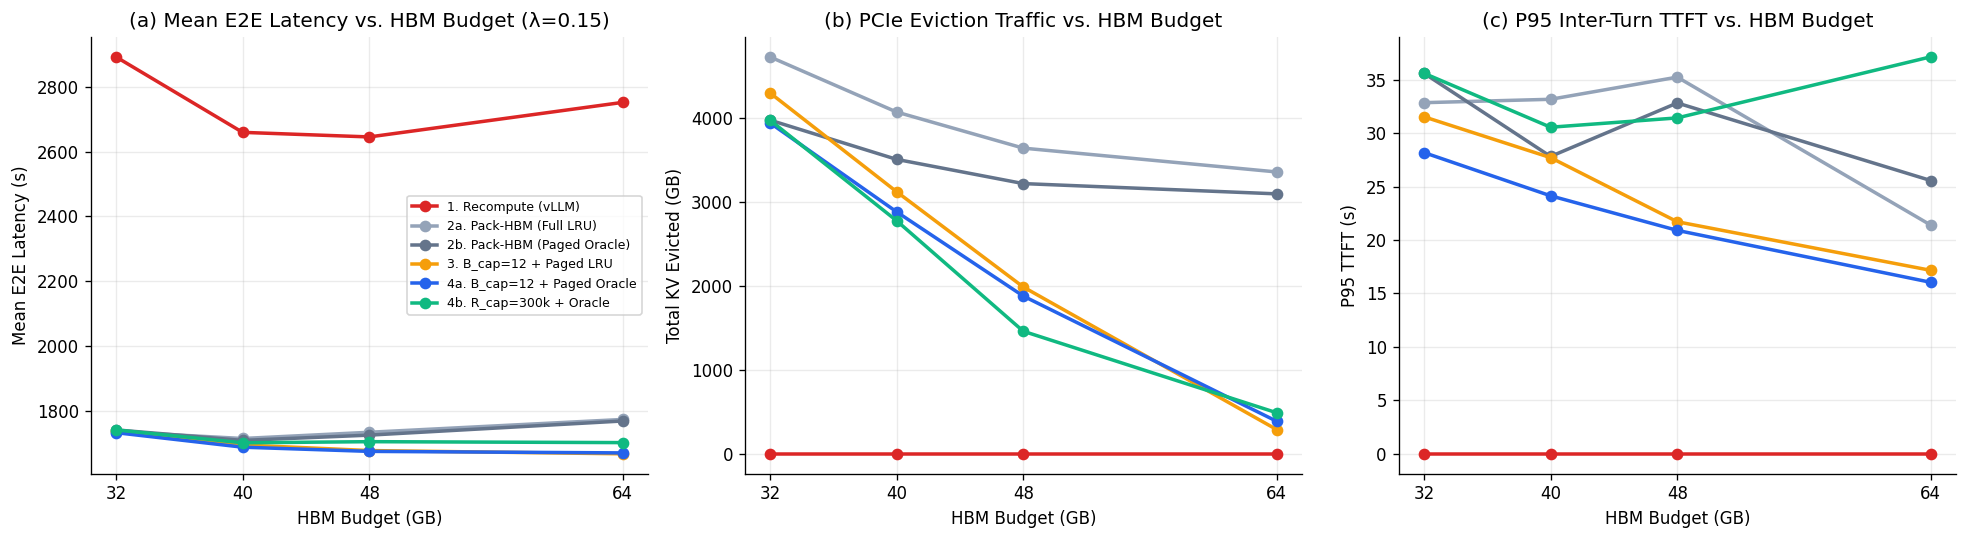

In [3]:
# Plot Experiment 1: MeanE2E, EvictGB, and TTFT p95 across HBM budgets
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))
x = np.arange(len(hbms))

for lbl, _, _, col in policies:
    e2e = [res_hbm[f"{h:.0f}G|{lbl}"]["mean_e2e_s"] for h in hbms]
    evg = [res_hbm[f"{h:.0f}G|{lbl}"]["total_evicted_gb"] for h in hbms]
    tp95 = [res_hbm[f"{h:.0f}G|{lbl}"]["ttft_p95"] for h in hbms]
    axes[0].plot(hbms, e2e, marker="o", lw=2.1, label=lbl, color=col)
    axes[1].plot(hbms, evg, marker="o", lw=2.1, label=lbl, color=col)
    axes[2].plot(hbms, tp95, marker="o", lw=2.1, label=lbl, color=col)

axes[0].set_title("(a) Mean E2E Latency vs. HBM Budget (λ=0.15)")
axes[0].set_xlabel("HBM Budget (GB)")
axes[0].set_ylabel("Mean E2E Latency (s)")
axes[0].set_xticks(hbms)
axes[0].legend(fontsize=7.5)

axes[1].set_title("(b) PCIe Eviction Traffic vs. HBM Budget")
axes[1].set_xlabel("HBM Budget (GB)")
axes[1].set_ylabel("Total KV Evicted (GB)")
axes[1].set_xticks(hbms)

axes[2].set_title("(c) P95 Inter-Turn TTFT vs. HBM Budget")
axes[2].set_xlabel("HBM Budget (GB)")
axes[2].set_ylabel("P95 TTFT (s)")
axes[2].set_xticks(hbms)

plt.tight_layout()
plt.show()

=== High Load (lambda = 0.25) ===
HBM  | Policy                      | Done  | MeanE2E   | LastDone  | EvictGB   | TTFT    | TTFTp95  | Stall%
------------------------------------------------------------------------------------------------------------
 48G | 1. Recompute (vLLM)         | 40/40 |  2680.6 s |  5249.9 s |     0.0 G |  0.00 s |   0.00 s |  0.00%
 48G | 2a. Pack-HBM (Full LRU)     | 40/40 |  1751.8 s |  3681.7 s |  3685.1 G | 11.17 s |  25.80 s |  0.20%
 48G | 2b. Pack-HBM (Paged Oracle) | 40/40 |  1756.8 s |  3710.8 s |  3401.7 G | 11.20 s |  28.32 s |  0.41%
 48G | 3. B_cap=12 + Paged LRU     | 40/40 |  1708.8 s |  3837.3 s |  1963.1 G |  5.99 s |  21.04 s |  0.14%
 48G | 4a. B_cap=12 + Paged Oracle | 40/40 |  1709.9 s |  3824.4 s |  1862.7 G |  6.06 s |  24.00 s |  0.16%
 48G | 4b. R_cap=300k + Oracle     | 40/40 |  1727.1 s |  3913.1 s |  1565.0 G | 10.10 s |  30.71 s |  0.08%
----------------------------------------------------------------------------------------------

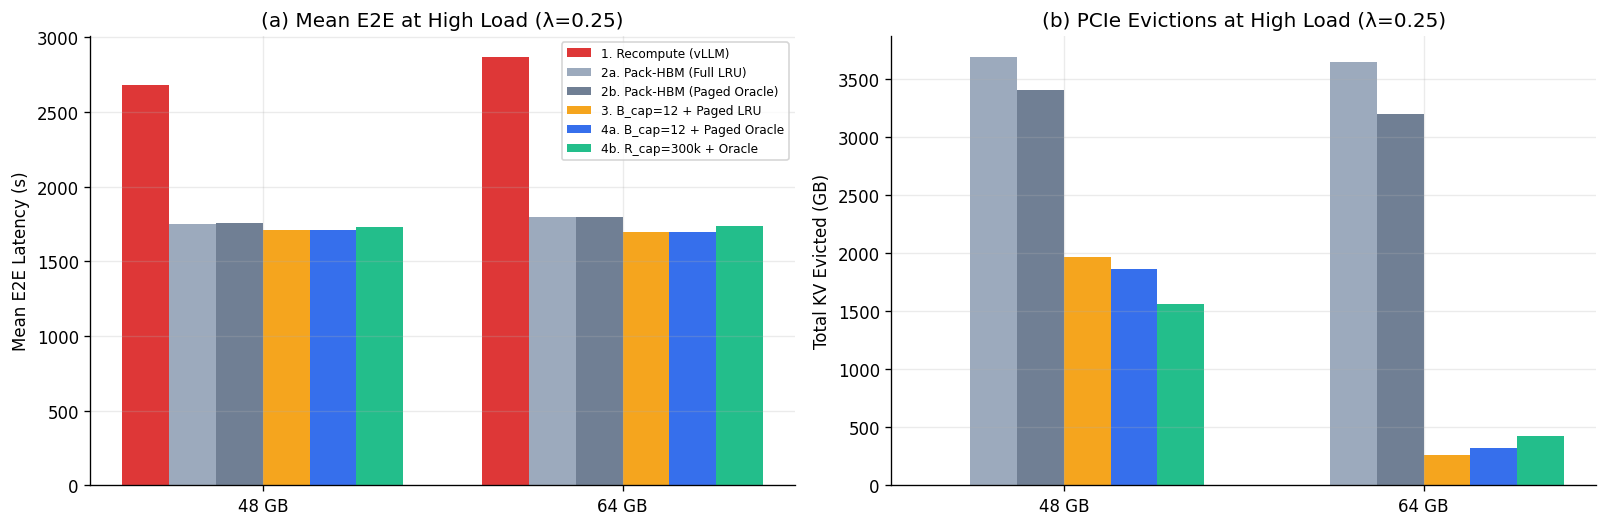

In [4]:
# Experiment 2: Higher Arrival Rate Stress Test (lambda = 0.25 at 48 GB and 64 GB)
hi_rate = 0.25
hi_hbms = [48.0, 64.0]
hi_tasks = []
for h in hi_hbms:
    for lbl, bp, kw, _ in policies:
        hi_tasks.append((f"{h:.0f}G|{lbl}", bp, h, hi_rate, n_req, seed, max_time, trace_path, kw))

res_hi = {}
with ProcessPoolExecutor() as ex:
    for k, s in ex.map(run_capped_sim, hi_tasks):
        res_hi[k] = s

print(f"=== High Load (lambda = {hi_rate}) ===")
print(hdr)
print("-" * len(hdr))
for h in hi_hbms:
    for lbl, _, _, _ in policies:
        s = res_hi[f"{h:.0f}G|{lbl}"]
        ss = s["state_seconds"]
        stall_pct = 100.0 * ss["STALL"] / max(1e-9, sum(ss.values()))
        print(f"{h:3.0f}G | {lbl:27s} | {s['done']:2d}/{s['total_requests']:2d} | {s['mean_e2e_s']:7.1f} s | "
              f"{s['makespan_done_s']:7.1f} s | {s['total_evicted_gb']:7.1f} G | "
              f"{s['ttft_mean']:5.2f} s | {s['ttft_p95']:6.2f} s | {stall_pct:5.2f}%")
    print("-" * len(hdr))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
xh = np.arange(len(hi_hbms))
w = 0.13
offs = np.linspace(-2.5*w, 2.5*w, len(policies))
for off, (lbl, _, _, col) in zip(offs, policies):
    vals_e2e = [res_hi[f"{h:.0f}G|{lbl}"]["mean_e2e_s"] for h in hi_hbms]
    vals_ev = [res_hi[f"{h:.0f}G|{lbl}"]["total_evicted_gb"] for h in hi_hbms]
    axes[0].bar(xh + off, vals_e2e, w, label=lbl, color=col, alpha=0.92)
    axes[1].bar(xh + off, vals_ev, w, label=lbl, color=col, alpha=0.92)

axes[0].set_xticks(xh); axes[0].set_xticklabels(["48 GB", "64 GB"])
axes[0].set_ylabel("Mean E2E Latency (s)"); axes[0].set_title("(a) Mean E2E at High Load (λ=0.25)")
axes[0].legend(fontsize=7.3, loc="upper right")

axes[1].set_xticks(xh); axes[1].set_xticklabels(["48 GB", "64 GB"])
axes[1].set_ylabel("Total KV Evicted (GB)"); axes[1].set_title("(b) PCIe Evictions at High Load (λ=0.25)")
plt.tight_layout()
plt.show()

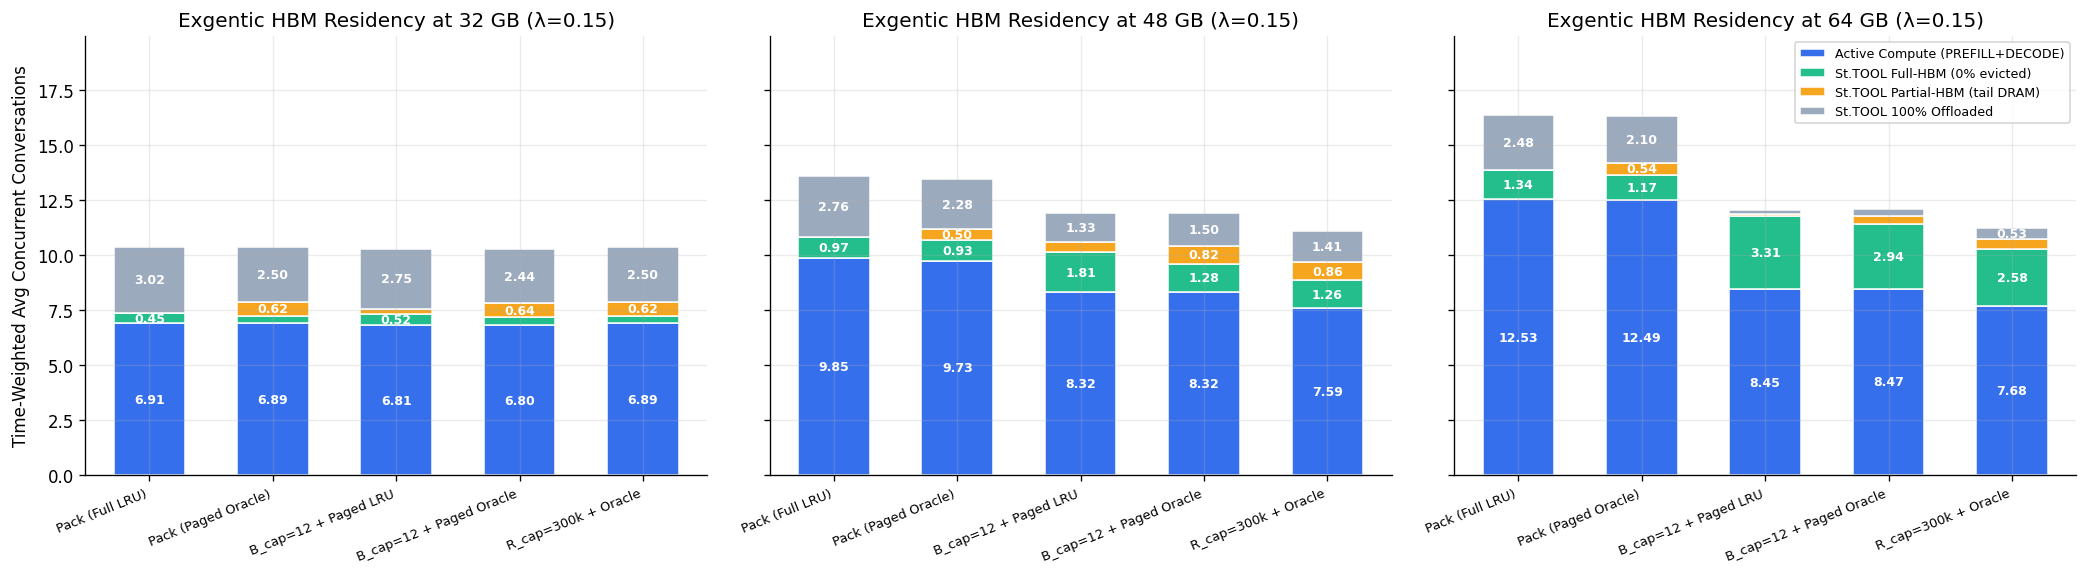

HBM  | Policy                      | Active  | ToolFull | ToolPart | ToolOff  | Reloads
----------------------------------------------------------------------------------
 32G | 2a. Pack-HBM (Full LRU)     |    6.91 |     0.45 |     0.00 |     3.02 |    1316
 32G | 2b. Pack-HBM (Paged Oracle) |    6.89 |     0.35 |     0.62 |     2.50 |    2997
 32G | 3. B_cap=12 + Paged LRU     |    6.81 |     0.52 |     0.22 |     2.75 |    1685
 32G | 4a. B_cap=12 + Paged Oracle |    6.80 |     0.38 |     0.64 |     2.44 |    2695
 32G | 4b. R_cap=300k + Oracle     |    6.89 |     0.35 |     0.62 |     2.50 |    2895
----------------------------------------------------------------------------------
 48G | 2a. Pack-HBM (Full LRU)     |    9.85 |     0.97 |     0.00 |     2.76 |    1065
 48G | 2b. Pack-HBM (Paged Oracle) |    9.73 |     0.93 |     0.50 |     2.28 |    2378
 48G | 3. B_cap=12 + Paged LRU     |    8.32 |     1.81 |     0.45 |     1.33 |     909
 48G | 4a. B_cap=12 + Paged Oracle |    8.

In [5]:
# Experiment 3: HBM Residency Breakdown on Exgentic SWE-bench (32, 48, 64 GB)
fig, axes = plt.subplots(1, 3, figsize=(17.5, 4.9), sharey=True)
show_policies = [p for p in policies if 'Recompute' not in p[0]]
for ax, hbm in zip(axes, [32.0, 48.0, 64.0]):
    lbls, act_c, full_t, part_t, off_t = [], [], [], [], []
    for lbl, _, _, _ in show_policies:
        rs = res_hbm[f'{hbm:.0f}G|{lbl}']['residency_seconds']
        wall = max(1e-9, rs['active_wall'])
        short = lbl.replace('2a. Pack-HBM ', 'Pack ').replace('2b. Pack-HBM ', 'Pack ').replace('3. ', '').replace('4a. ', '').replace('4b. ', '')
        lbls.append(short)
        act_c.append(rs['active_compute'] / wall)
        full_t.append(rs['tool_full_hbm'] / wall)
        part_t.append(rs['tool_partial_hbm'] / wall)
        off_t.append(rs['tool_offloaded_only'] / wall)
    xb = np.arange(len(lbls))
    bot = np.zeros(len(lbls))
    for name, arr, col in [
        ('Active Compute (PREFILL+DECODE)', act_c, '#2563eb'),
        ('St.TOOL Full-HBM (0% evicted)',   full_t, '#10b981'),
        ('St.TOOL Partial-HBM (tail DRAM)', part_t, '#f59e0b'),
        ('St.TOOL 100% Offloaded',          off_t, '#94a3b8'),
    ]:
        a = np.array(arr)
        ax.bar(xb, a, width=0.58, bottom=bot, label=name, color=col, alpha=0.92, edgecolor='white')
        for xi, v, b in zip(xb, a, bot):
            if v >= 0.45:
                ax.text(xi, b + v / 2.0, f'{v:.2f}', ha='center', va='center', color='white', fontsize=7.5, fontweight='bold')
        bot += a
    ax.set_xticks(xb); ax.set_xticklabels(lbls, fontsize=7.8, rotation=22, ha='right')
    ax.set_title(f'Exgentic HBM Residency at {hbm:.0f} GB (λ=0.15)')
    if hbm == 32.0:
        ax.set_ylabel('Time-Weighted Avg Concurrent Conversations')
    ax.set_ylim(0, max(bot) * 1.22)
axes[2].legend(fontsize=7.6, loc='upper right')
plt.tight_layout()
plt.show()

print(f"{'HBM':4s} | {'Policy':27s} | {'Active':7s} | {'ToolFull':8s} | {'ToolPart':8s} | {'ToolOff':8s} | {'Reloads':7s}")
print('-' * 82)
for hbm in [32.0, 48.0, 64.0]:
    for lbl, _, _, _ in show_policies:
        s = res_hbm[f'{hbm:.0f}G|{lbl}']
        rs = s['residency_seconds']
        w = max(1e-9, rs['active_wall'])
        print(f"{hbm:3.0f}G | {lbl:27s} | {rs['active_compute']/w:7.2f} | {rs['tool_full_hbm']/w:8.2f} | "
              f"{rs['tool_partial_hbm']/w:8.2f} | {rs['tool_offloaded_only']/w:8.2f} | {s['total_reloads']:7d}")
    print('-' * 82)


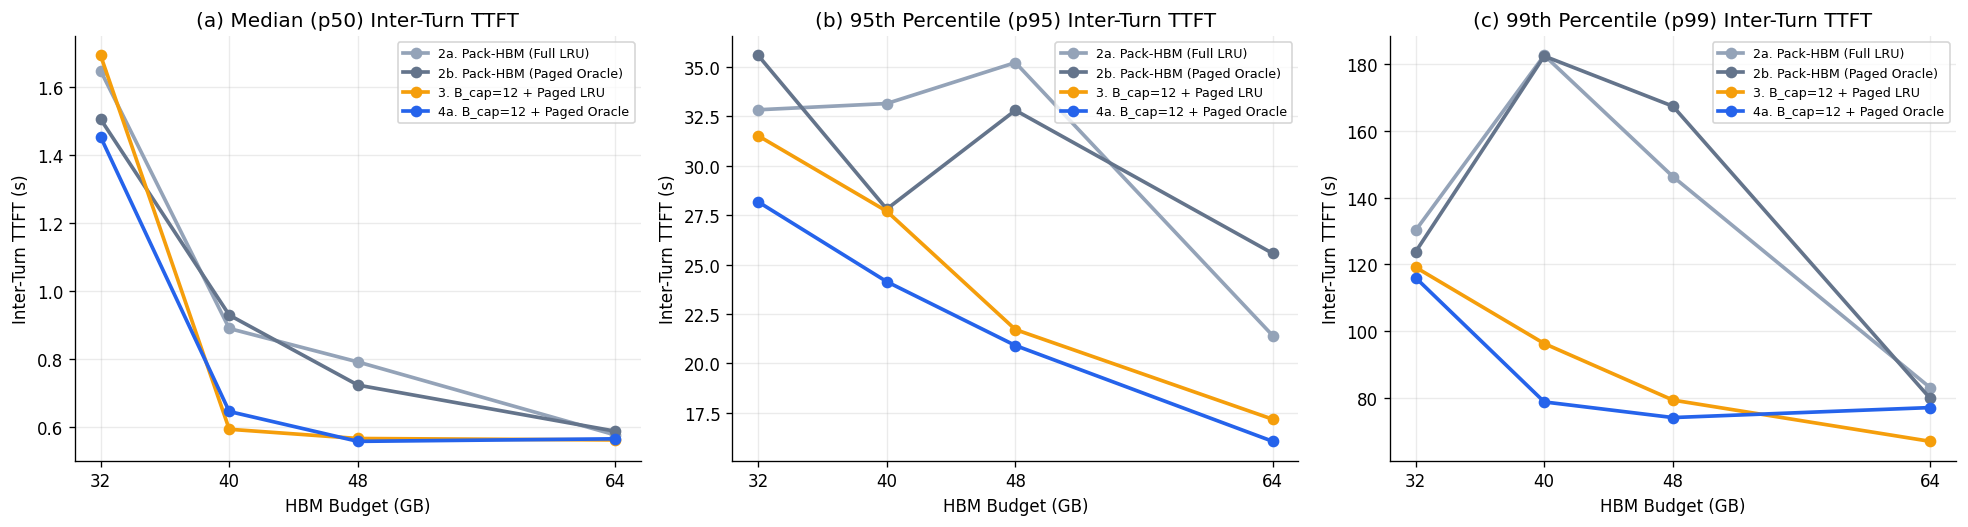

In [6]:
# Experiment 4: Inter-Turn TTFT Percentiles (p50, p95, p99) vs. HBM Budget
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.5))
ttft_policies = [p for p in policies if p[0] not in ('1. Recompute (vLLM)', '4b. R_cap=300k + Oracle')]
for ax, (key, title) in zip(axes, [
    ('ttft_p50', '(a) Median (p50) Inter-Turn TTFT'),
    ('ttft_p95', '(b) 95th Percentile (p95) Inter-Turn TTFT'),
    ('ttft_p99', '(c) 99th Percentile (p99) Inter-Turn TTFT'),
]):
    for lbl, _, _, col in ttft_policies:
        vals = [res_hbm[f'{h:.0f}G|{lbl}'][key] for h in hbms]
        ax.plot(hbms, vals, marker='o', lw=2.2, label=lbl, color=col)
    ax.set_title(title)
    ax.set_xlabel('HBM Budget (GB)')
    ax.set_ylabel('Inter-Turn TTFT (s)')
    ax.set_xticks(hbms)
    ax.legend(fontsize=7.6, loc='upper right')

plt.tight_layout()
plt.show()


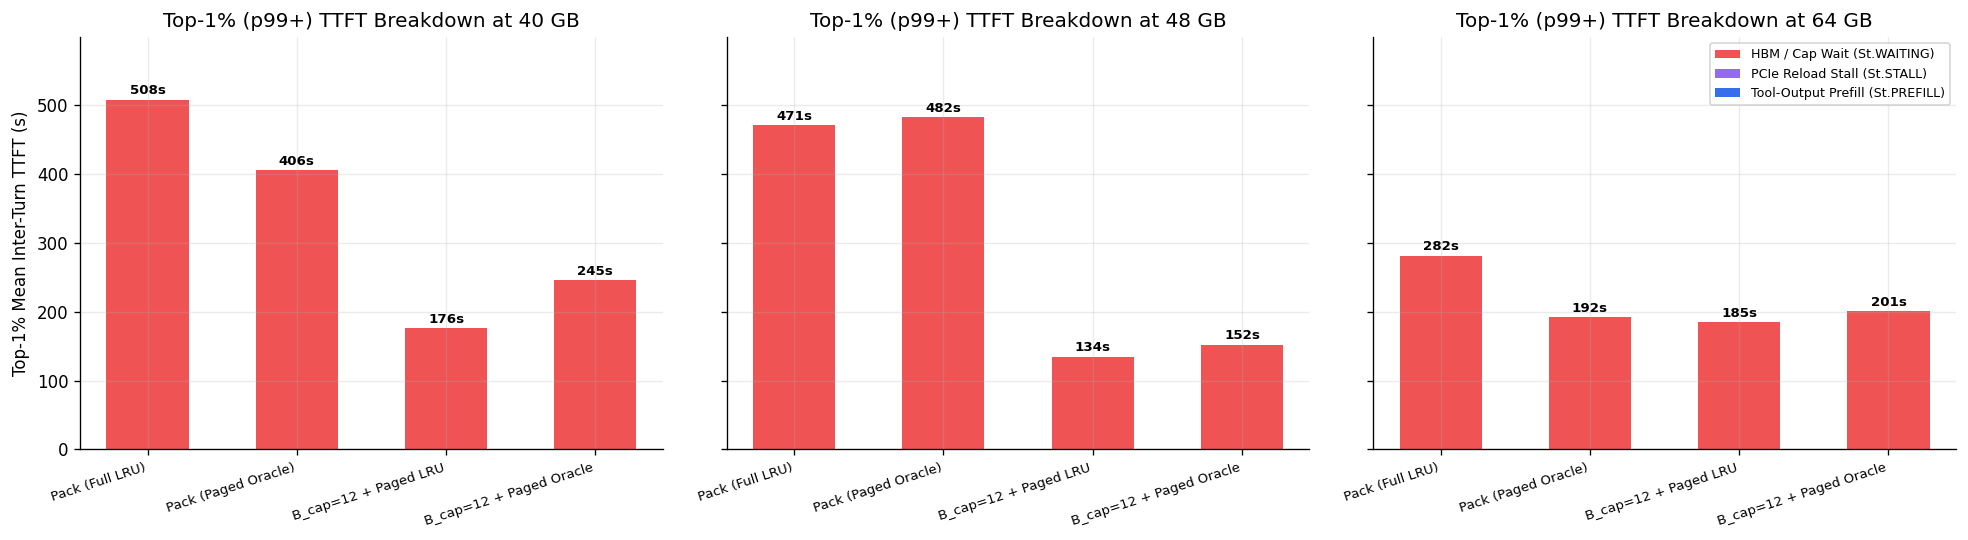

In [7]:
# Experiment 5: Top-1% (p99+) TTFT Decomposition Across 40, 48, 64 GB
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6), sharey=True)
ttft_policies = [p for p in policies if p[0] not in ('1. Recompute (vLLM)', '4b. R_cap=300k + Oracle')]
short_lbls = [p[0].replace('2a. Pack-HBM ', 'Pack ').replace('2b. Pack-HBM ', 'Pack ').replace('3. ', '').replace('4a. ', '') for p in ttft_policies]
xb = np.arange(len(ttft_policies))

for ax, hbm in zip(axes, [40.0, 48.0, 64.0]):
    pw = np.array([res_hbm[f'{hbm:.0f}G|{lbl}']['ttft_decomp']['p99_wait'] for lbl, _, _, _ in ttft_policies])
    ps = np.array([res_hbm[f'{hbm:.0f}G|{lbl}']['ttft_decomp']['p99_stall'] for lbl, _, _, _ in ttft_policies])
    pp = np.array([res_hbm[f'{hbm:.0f}G|{lbl}']['ttft_decomp']['p99_prefill'] for lbl, _, _, _ in ttft_policies])
    ax.bar(xb, pw, 0.55, label='HBM / Cap Wait (St.WAITING)', color='#ef4444', alpha=0.92)
    ax.bar(xb, ps, 0.55, bottom=pw, label='PCIe Reload Stall (St.STALL)', color='#8b5cf6', alpha=0.92)
    ax.bar(xb, pp, 0.55, bottom=pw+ps, label='Tool-Output Prefill (St.PREFILL)', color='#2563eb', alpha=0.92)
    for xi, tot in zip(xb, pw + ps + pp):
        ax.text(xi, tot + 3.5, f'{tot:.0f}s', ha='center', va='bottom', fontsize=8, fontweight='bold')
    ax.set_xticks(xb); ax.set_xticklabels(short_lbls, fontsize=8, rotation=18, ha='right')
    ax.set_title(f'Top-1% (p99+) TTFT Breakdown at {hbm:.0f} GB')
    if hbm == 40.0:
        ax.set_ylabel('Top-1% Mean Inter-Turn TTFT (s)')
axes[0].set_ylim(0, max(res_hbm[f'{h:.0f}G|{l}']['ttft_decomp']['p99_wait'] + res_hbm[f'{h:.0f}G|{l}']['ttft_decomp']['p99_stall'] + res_hbm[f'{h:.0f}G|{l}']['ttft_decomp']['p99_prefill'] for h in [40.0, 48.0, 64.0] for l, _, _, _ in ttft_policies) * 1.18)
axes[2].legend(fontsize=7.6, loc='upper right')
plt.tight_layout()
plt.show()
